# Training Results — LULC Segmentation from Sentinel-1 SAR

This notebook visualises the training run and evaluates the final model on the held-out test split.

**Run order:** execute cells top-to-bottom after `python -m src.training.train` has completed and produced:
- `checkpoints/best_model.pth`
- `checkpoints/history.json`
- `checkpoints/test_results.json`

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import numpy as np
import torch

# Make sure project root is on the path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

CHECKPOINT_DIR = PROJECT_ROOT / 'checkpoints'
PATCH_DIR      = PROJECT_ROOT / 'data' / 'patches'

print('Project root:', PROJECT_ROOT)

Project root: /home/jovyan/exam_Martin


## 1. Training curves

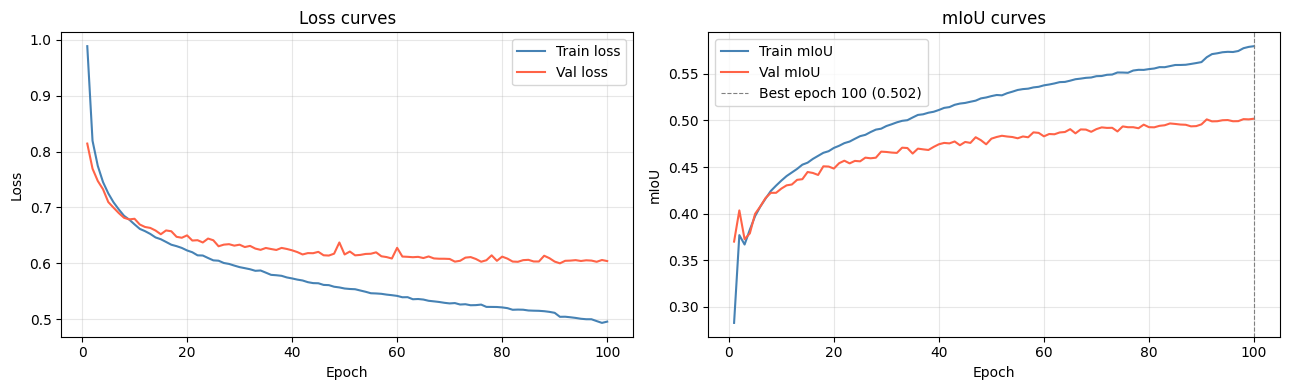

Best val mIoU: 0.5019 at epoch 100


In [2]:
with open(CHECKPOINT_DIR / 'history.json') as f:
    history = json.load(f)

epochs      = [r['epoch']      for r in history]
train_loss  = [r['train_loss'] for r in history]
val_loss    = [r['val_loss']   for r in history]
train_miou  = [r['train_miou'] for r in history]
val_miou    = [r['val_miou']   for r in history]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(epochs, train_loss, label='Train loss', color='steelblue')
ax1.plot(epochs, val_loss,   label='Val loss',   color='tomato')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss')
ax1.set_title('Loss curves')
ax1.legend(); ax1.grid(alpha=0.3)

ax2.plot(epochs, train_miou, label='Train mIoU', color='steelblue')
ax2.plot(epochs, val_miou,   label='Val mIoU',   color='tomato')
best_epoch = history[int(np.argmax(val_miou))]['epoch']
best_val   = max(val_miou)
ax2.axvline(best_epoch, color='grey', linestyle='--', linewidth=0.8,
            label=f'Best epoch {best_epoch} ({best_val:.3f})')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('mIoU')
ax2.set_title('mIoU curves')
ax2.legend(); ax2.grid(alpha=0.3)

fig.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'training_curves.png', dpi=150)
plt.show()
print(f'Best val mIoU: {best_val:.4f} at epoch {best_epoch}')

## 2. Test-set metrics

In [3]:
from src.data.download import WORLDCOVER_CLASSES

CLASS_NAMES = [WORLDCOVER_CLASSES[k] for k in sorted(WORLDCOVER_CLASSES)]

with open(CHECKPOINT_DIR / 'test_results.json') as f:
    results = json.load(f)

print(f"Overall Accuracy (OA) : {results['oa']:.4f}")
print(f"mean IoU (mIoU)       : {results['miou']:.4f}")
print()
print(f"{'Class':<30s}  {'IoU':>6s}  {'F1':>6s}")
print('-' * 46)
for i, name in enumerate(CLASS_NAMES):
    iou = results['iou_per_class'][i]
    f1  = results['f1_per_class'][i]
    print(f"{name:<30s}  {iou:6.3f}  {f1:6.3f}")

Overall Accuracy (OA) : 0.7384
mean IoU (mIoU)       : 0.4993

Class                              IoU      F1
----------------------------------------------
Tree cover                       0.769   0.869
Shrubland                        0.477   0.646
Grassland                        0.623   0.768
Cropland                         0.519   0.683
Built-up                         0.621   0.766
Bare / sparse vegetation         0.423   0.594
Snow and ice                     0.689   0.816
Permanent water bodies           0.339   0.507
Herbaceous wetland               0.456   0.626
Mangroves                        0.360   0.529
Moss and lichen                  0.217   0.356


## 3. Per-class IoU bar chart

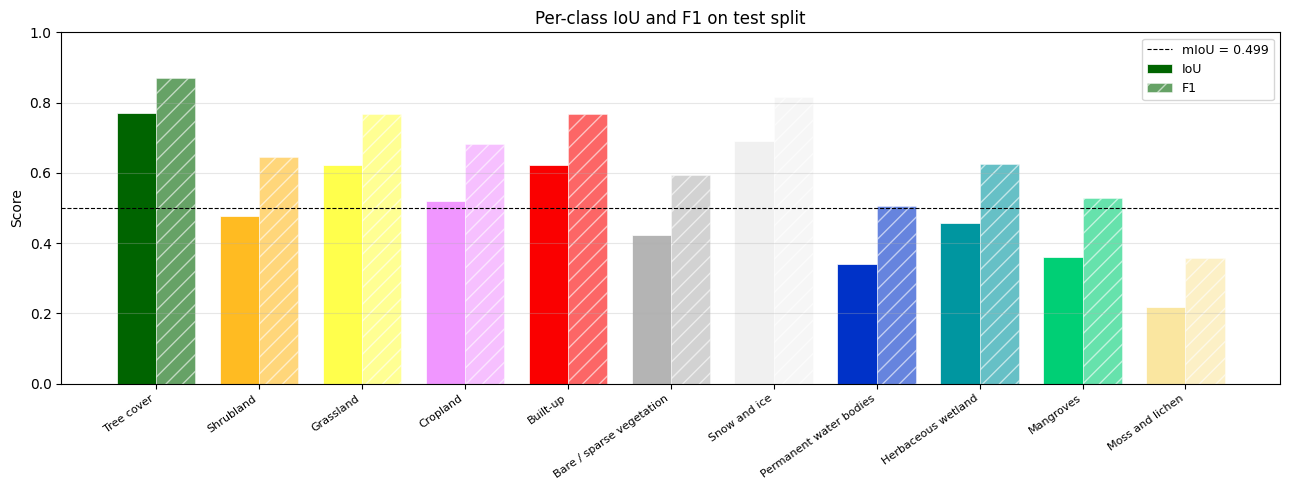

In [4]:
# ESA WorldCover colour palette
_PALETTE_RGB = [
    (0,100,0),(255,187,34),(255,255,76),(240,150,255),(250,0,0),
    (180,180,180),(240,240,240),(0,50,200),(0,150,160),(0,207,117),(250,230,160)
]
_PALETTE = [(r/255,g/255,b/255) for r,g,b in _PALETTE_RGB]

iou_vals = results['iou_per_class']
f1_vals  = results['f1_per_class']

x = np.arange(len(CLASS_NAMES))
w = 0.38

fig, ax = plt.subplots(figsize=(13, 5))
bars1 = ax.bar(x - w/2, iou_vals, w, label='IoU', color=_PALETTE, edgecolor='white', linewidth=0.5)
bars2 = ax.bar(x + w/2, f1_vals,  w, label='F1',  color=_PALETTE, edgecolor='white', linewidth=0.5,
               alpha=0.6, hatch='//')

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=35, ha='right', fontsize=8)
ax.set_ylim(0, 1.0)
ax.set_ylabel('Score')
ax.set_title('Per-class IoU and F1 on test split')
ax.axhline(results['miou'], color='black', linestyle='--', linewidth=0.8,
           label=f"mIoU = {results['miou']:.3f}")
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'per_class_metrics.png', dpi=150)
plt.show()

## 4. Sample predictions vs ground truth

In [5]:
from src.models.unet import build_unet

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ckpt   = torch.load(CHECKPOINT_DIR / 'best_model.pth', map_location=device)
model  = build_unet(encoder_name=ckpt.get('encoder_name', 'resnet34'), encoder_weights=None)
model.load_state_dict(ckpt['model_state_dict'])
model.eval().to(device)
print(f'Loaded checkpoint from epoch {ckpt["epoch"]}  (val mIoU={ckpt["val_miou"]:.4f})')

Loaded checkpoint from epoch 100  (val mIoU=0.5019)


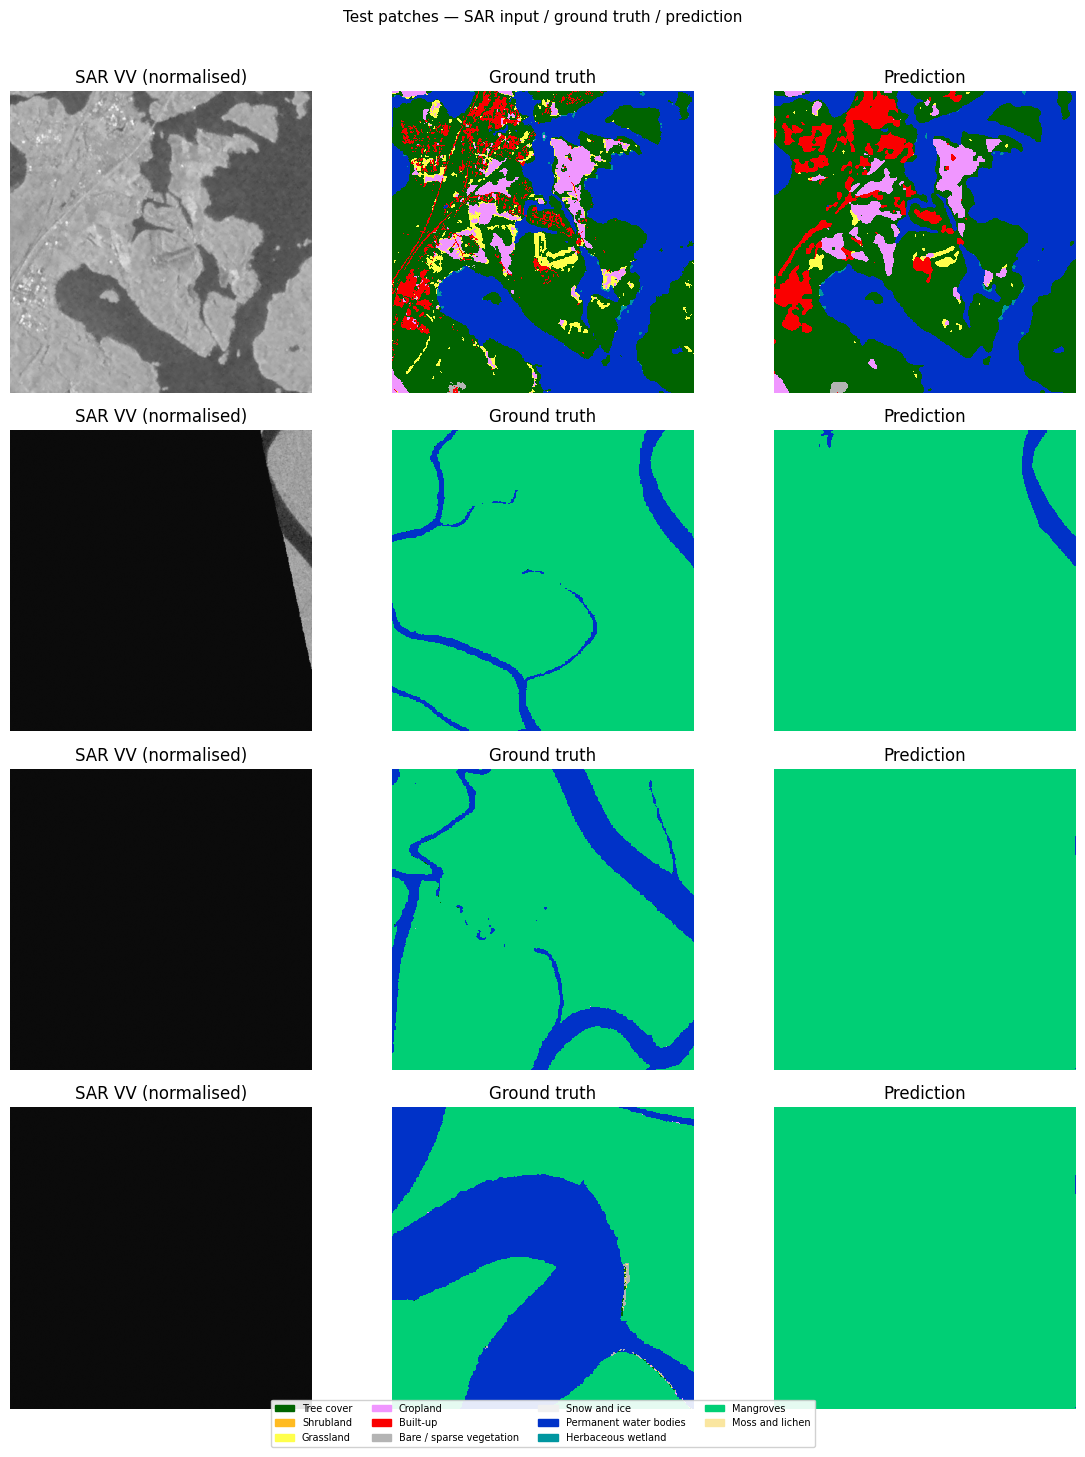

In [6]:
from src.data.download import IGNORE_INDEX, NUM_CLASSES

_CMAP = mcolors.ListedColormap(_PALETTE + [(0.1, 0.1, 0.1)])

def pred_to_rgb(arr):
    display = arr.copy().astype(np.int32)
    display[display == IGNORE_INDEX] = NUM_CLASSES
    return _CMAP(np.clip(display, 0, NUM_CLASSES))

test_files = sorted((PATCH_DIR / 'test').glob('patch_*.npz'))[:4]

fig, axes = plt.subplots(len(test_files), 3, figsize=(12, 3.5 * len(test_files)))
if len(test_files) == 1:
    axes = [axes]

legend_patches = [mpatches.Patch(color=_PALETTE[i], label=CLASS_NAMES[i])
                  for i in range(NUM_CLASSES)]

for row, f in enumerate(test_files):
    data = np.load(f)
    sar  = torch.from_numpy(data['sar']).unsqueeze(0).to(device)
    lbl  = data['lbl']

    with torch.no_grad():
        logits = model(sar)
    pred = logits.argmax(dim=1).squeeze(0).cpu().numpy()

    # VV band as grayscale for SAR visualisation
    ax0, ax1, ax2 = axes[row]
    ax0.imshow(data['sar'][0], cmap='gray', vmin=-2, vmax=2)
    ax0.set_title('SAR VV (normalised)'); ax0.axis('off')

    ax1.imshow(pred_to_rgb(lbl), interpolation='nearest')
    ax1.set_title('Ground truth'); ax1.axis('off')

    ax2.imshow(pred_to_rgb(pred), interpolation='nearest')
    ax2.set_title('Prediction'); ax2.axis('off')

fig.legend(handles=legend_patches, loc='lower center', ncol=4, fontsize=7,
           bbox_to_anchor=(0.5, -0.02), framealpha=0.9)
fig.suptitle('Test patches — SAR input / ground truth / prediction', fontsize=11, y=1.01)
fig.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'sample_predictions.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Confusion matrix (normalised by true class)

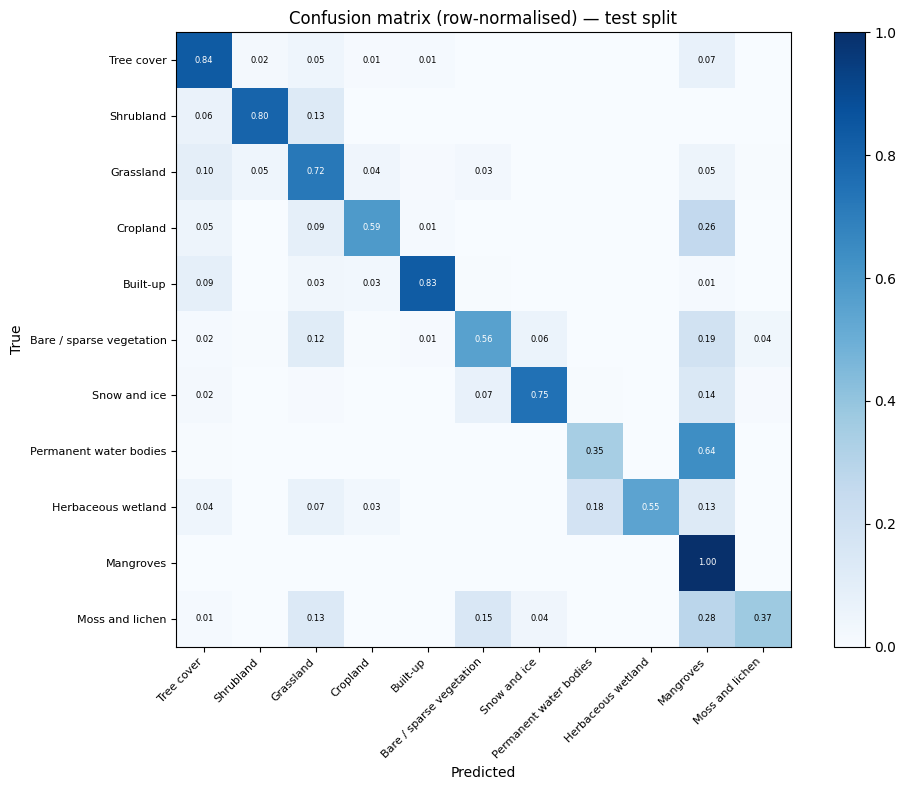

In [8]:
from src.data.dataset import LULCDataset
from torch.utils.data import DataLoader

test_ds     = LULCDataset(PATCH_DIR / 'test')
test_loader = DataLoader(test_ds, batch_size=4, shuffle=False, num_workers=0)

conf = np.zeros((NUM_CLASSES, NUM_CLASSES), dtype=np.int64)

model.eval()
with torch.no_grad():
    for sar, lbl in test_loader:
        sar  = sar.to(device)
        pred = model(sar).argmax(dim=1).cpu().numpy().ravel()
        true = lbl.numpy().ravel()
        valid = true != IGNORE_INDEX
        # Vectorised: encode (true, pred) pair as a single index, count with np.bincount
        conf += np.bincount(
            NUM_CLASSES * true[valid].astype(np.int64) + pred[valid].astype(np.int64),
            minlength=NUM_CLASSES * NUM_CLASSES,
        ).reshape(NUM_CLASSES, NUM_CLASSES)

# Normalise by row (true class)
row_sums = conf.sum(axis=1, keepdims=True)
conf_norm = np.where(row_sums > 0, conf / row_sums, 0)

# Only show classes that appear in the test set
present = conf.sum(axis=1) > 0
names_p = [CLASS_NAMES[i] for i in range(NUM_CLASSES) if present[i]]
conf_p  = conf_norm[np.ix_(present, present)]

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(conf_p, vmin=0, vmax=1, cmap='Blues')
plt.colorbar(im, ax=ax, fraction=0.04)
ticks = np.arange(len(names_p))
ax.set_xticks(ticks); ax.set_yticks(ticks)
ax.set_xticklabels(names_p, rotation=45, ha='right', fontsize=8)
ax.set_yticklabels(names_p, fontsize=8)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion matrix (row-normalised) — test split')
for i in range(len(names_p)):
    for j in range(len(names_p)):
        v = conf_p[i, j]
        if v > 0.01:
            ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                    fontsize=6, color='white' if v > 0.5 else 'black')
fig.tight_layout()
plt.savefig(CHECKPOINT_DIR / 'confusion_matrix.png', dpi=150)
plt.show()